# 113 · Latency budgets: single-system vs dual-system control loops (simulated)

In [1]:
import time, numpy as np, matplotlib.pyplot as plt

def make_net(width, depth=3, d_in=64, seed=0):
    rng = np.random.default_rng(seed)
    layers = [rng.standard_normal((d_in, width)).astype(np.float32) / np.sqrt(d_in)]
    for _ in range(depth - 1):
        layers.append(rng.standard_normal((width, width)).astype(np.float32) / np.sqrt(width))
    return layers

def forward(layers, x):
    for W in layers:
        x = np.maximum(x @ W, 0.0)
    return x

def timed(fn):
    t0 = time.perf_counter(); out = fn(); return out, time.perf_counter() - t0

fast, slow = make_net(64), make_net(2048, depth=6)
x = np.random.randn(1, 64).astype(np.float32)

In [2]:
t_fast = np.median([timed(lambda: forward(fast, x))[1] for _ in range(200)])
t_slow = np.median([timed(lambda: forward(slow, x))[1] for _ in range(50)])
print(f"System 1 (small) forward: {t_fast * 1e3:.3f} ms | System 2 (large) forward: {t_slow * 1e3:.2f} ms  ({t_slow / t_fast:.0f}x)")
BUDGET = 3 * t_fast + t_slow * 0.5
print(f"control-cycle budget for this demo: {BUDGET * 1e3:.2f} ms")

System 1 (small) forward: 0.022 ms | System 2 (large) forward: 15.30 ms  (683x)
control-cycle budget for this demo: 7.71 ms


In [3]:
def run_single(n=400):
    return np.array([timed(lambda: forward(slow, x))[1] for _ in range(n)])

def run_dual(n=400, k=25):
    lat = []
    for c in range(n):
        def cycle():
            if c % k == 0:
                forward(slow, x)
            return forward(fast, x)
        lat.append(timed(cycle)[1])
    return np.array(lat)

def run_decoupled(n=400, k=25):
    fast_lat, slow_clock = [], 0.0
    for c in range(n):
        if c % k == 0:
            _, ts = timed(lambda: forward(slow, x)); slow_clock += ts
        _, tf = timed(lambda: forward(fast, x)); fast_lat.append(tf)
    return np.array(fast_lat)

runs = {"single system (big net every cycle)": run_single(), "dual system, same thread (slow every 25)": run_dual(), "dual system, decoupled clocks": run_decoupled()}

single system (big net every cycle)          median  14.489 ms  p99  36.202 ms  max  53.936 ms  missed budget 100%
dual system, same thread (slow every 25)     median   0.025 ms  p99  14.163 ms  max  21.019 ms  missed budget 4%
dual system, decoupled clocks                median   0.026 ms  p99   0.135 ms  max   0.600 ms  missed budget 0%


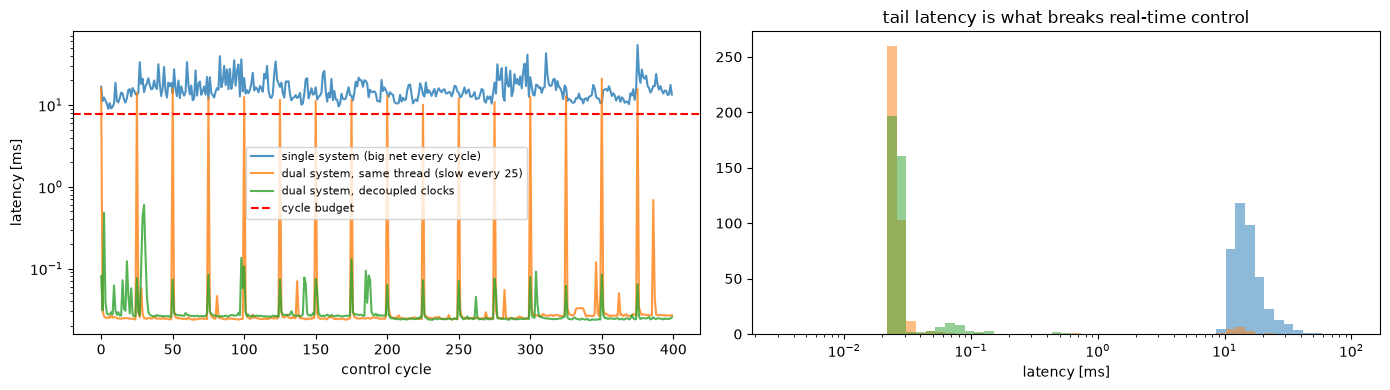

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for name, lat in runs.items():
    ax[0].plot(lat * 1e3, label=name, alpha=0.8)
    print(f"{name:44s} median {np.median(lat) * 1e3:7.3f} ms  p99 {np.percentile(lat, 99) * 1e3:7.3f} ms  max {lat.max() * 1e3:7.3f} ms  missed budget {np.mean(lat > BUDGET):.0%}")
ax[0].axhline(BUDGET * 1e3, c="r", ls="--", label="cycle budget"); ax[0].set_yscale("log"); ax[0].set_xlabel("control cycle"); ax[0].set_ylabel("latency [ms]"); ax[0].legend(fontsize=8)
for name, lat in runs.items():
    ax[1].hist(lat * 1e3, bins=np.logspace(-2.5, 2, 60), alpha=0.5, label=name)
ax[1].set_xscale("log"); ax[1].set_xlabel("latency [ms]"); ax[1].set_title("tail latency is what breaks real-time control"); plt.tight_layout(); plt.show()